# Practice Set 1 — programming solutions (Q5 and Q11)

These are the two programming questions in `PracticeSet1.tex`. Run the cells in order. The local `iris.data` file is from the [UCI Iris dataset](https://archive.ics.uci.edu/dataset/53/iris) (Fisher, 1936; CC BY 4.0). It is included so this notebook works offline. Requires NumPy and Matplotlib.


## Q5(a). What are the analytic gradient and Hessian of the Rosenbrock function?

**Answer.** Put $r=y-x^2$. For $f(x,y)=100r^2+(1-x)^2$, the chain rule gives

$$\frac{\partial f}{\partial x}=200r(-2x)+2(x-1)=-400x(y-x^2)+2(x-1),$$
$$\frac{\partial f}{\partial y}=200r.$$

Differentiating again,

$$\nabla^2 f(x,y)=\begin{bmatrix}1200x^2-400y+2&-400x\\-400x&200\end{bmatrix}.$$


## Q5(b). How do we code the gradient and Hessian?

**Answer.** The functions below match the requested `(x, y)` interface and return NumPy arrays.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from pathlib import Path

def f_rosenbrock(xy):
    x, y = xy
    return 100 * (y - x**2)**2 + (1 - x)**2

def Grad(x, y):
    """Return [df/dx, df/dy] at (x, y)."""
    return np.array([-400*x*(y-x**2) + 2*(x-1),
                     200*(y-x**2)], dtype=float)

def Hessian(x, y):
    """Return the 2-by-2 Hessian at (x, y)."""
    return np.array([[1200*x**2 - 400*y + 2, -400*x],
                     [-400*x, 200]], dtype=float)


## Q5(c). How do we implement multivariate Newton's method?

**Answer.** At each point solve $H_kp_k=-\nabla f(x_k)$ with `np.linalg.solve`, then set $x_{k+1}=x_k+p_k$. The history includes iteration 0 and the final point, so the number of Newton updates is `len(history)-1`. A singular Hessian ends the run without claiming convergence. This is the requested undamped Newton method; no optimization library is used.


In [2]:
def newton_method(f, grad, hess, x0, tol=1e-6, max_iter=50):
    """Return (final point, history) for undamped Newton iteration."""
    xk = np.asarray(x0, dtype=float).copy()
    if xk.shape != (2,):
        raise ValueError('x0 must have shape (2,)')
    history = []
    for k in range(max_iter + 1):
        g = grad(*xk)
        history.append({'k': k, 'x': xk.copy(), 'f': float(f(xk)),
                        'grad_norm': float(np.linalg.norm(g))})
        if history[-1]['grad_norm'] < tol or k == max_iter:
            break
        try:
            p = np.linalg.solve(hess(*xk), -g)
        except np.linalg.LinAlgError:
            break
        xk = xk + p
    return xk, history


## Q5(d). What happens from three initial guesses?

**Answer.** The next cell prints the convergence decision, update count, final point, and final value for each run. Each plot shows the full trajectory over logarithmically colored Rosenbrock contours.


(-1.2, 1.0): 6 updates; final = [1. 1.]; f = 3.433e-20; ||grad|| = 8.286e-09
(0.0, 0.0): 2 updates; final = [1. 1.]; f = 0.000e+00; ||grad|| = 0.000e+00
(2.0, 2.0): 5 updates; final = [1. 1.]; f = 8.332e-30; ||grad|| = 5.773e-15


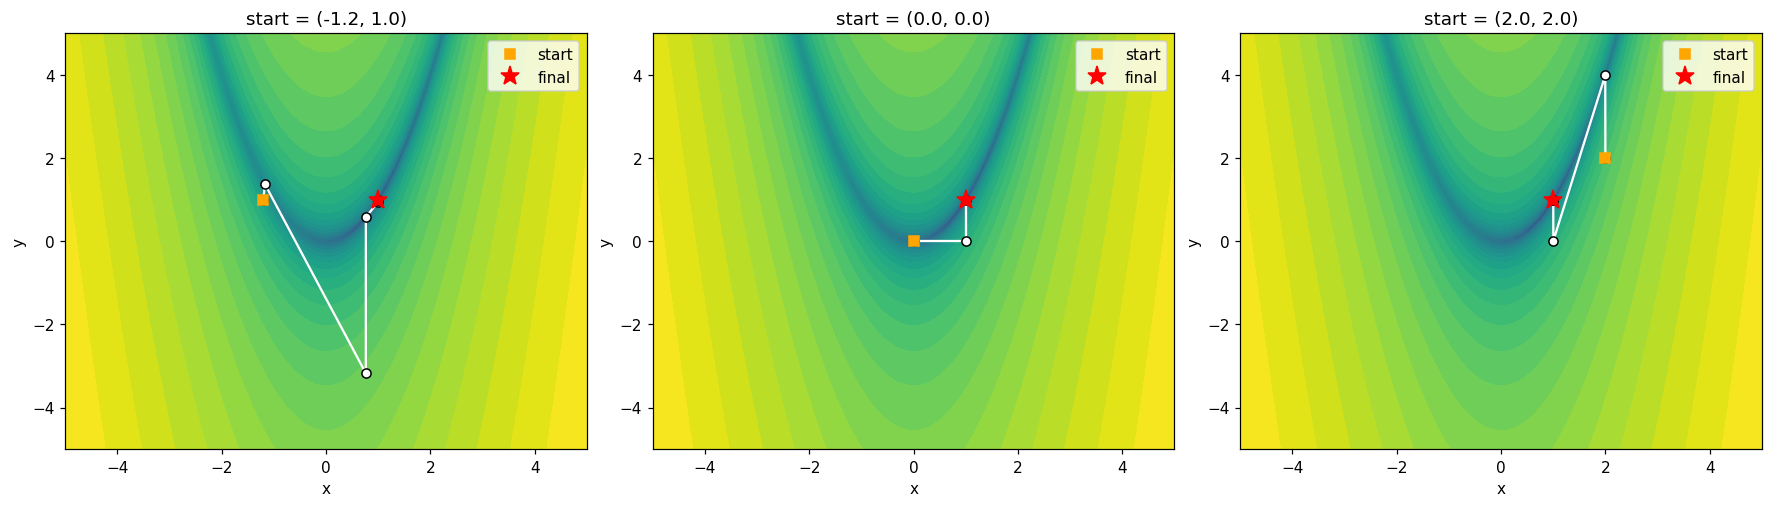

In [3]:
starts = [(-1.2, 1.0), (0.0, 0.0), (2.0, 2.0)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

for ax, start in zip(axes, starts):
    x_star, history = newton_method(f_rosenbrock, Grad, Hessian, start)
    path = np.array([row['x'] for row in history])
    # Include all iterates, even if an undamped step leaves the requested start domain.
    xlo, xhi = min(-5, path[:, 0].min() - .5), max(5, path[:, 0].max() + .5)
    ylo, yhi = min(-5, path[:, 1].min() - .5), max(5, path[:, 1].max() + .5)
    xx, yy = np.meshgrid(np.linspace(xlo, xhi, 300), np.linspace(ylo, yhi, 300))
    zz = 100*(yy-xx**2)**2 + (1-xx)**2
    ax.contourf(xx, yy, zz + 1e-3, levels=np.geomspace(1e-3, max(zz.max(), 1), 35),
                norm=LogNorm(vmin=1e-3, vmax=max(zz.max(), 1)), cmap='viridis')
    ax.plot(path[:, 0], path[:, 1], 'o-', color='white', markeredgecolor='black', lw=1.5)
    ax.plot(path[0, 0], path[0, 1], 's', color='orange', label='start')
    ax.plot(path[-1, 0], path[-1, 1], '*', color='red', ms=13, label='final')
    ax.set(xlabel='x', ylabel='y', title=f'start = {start}')
    ax.legend()
    converged = history[-1]['grad_norm'] < 1e-6
    status = f'{len(history)-1} updates' if converged else 'did not converge'
    print(f'{start}: {status}; final = {x_star}; '
          f'f = {f_rosenbrock(x_star):.3e}; '
          f'||grad|| = {history[-1]["grad_norm"]:.3e}')

plt.show()


**Observed behavior.** With these starts and a $10^{-6}$ gradient tolerance, Newton's method reaches $(1,1)$ in 6, 2, and 5 updates, respectively. The paths are sensitive to the start: from $(0,0)$ the objective first rises from 1 to 100, while from $(-1.2,1)$ it temporarily rises above 1400; full Newton steps need not decrease the objective. All three starts still converge within 50 updates. Counts refer to updates, excluding the initial point.


## Q11(a). How do we center the Iris measurements, and what is the mean?

**Answer.** Each row is one flower and the columns are sepal length, sepal width, petal length, and petal width (cm). The mean contains the average of each measurement over all 150 flowers. Subtracting it from every row centers each column at zero.


In [4]:
data_path = Path('iris.data')
if not data_path.exists():
    data_path = Path('ProblemsetSolutions/iris.data')
rows = [line.strip().split(',') for line in data_path.read_text().splitlines()
        if line.strip()]
X = np.array([[float(value) for value in row[:4]] for row in rows])
species = np.array([row[4].removeprefix('Iris-') for row in rows])
feature_names = ['sepal length', 'sepal width', 'petal length', 'petal width']
assert X.shape == (150, 4)
mu = X.mean(axis=0)
Xc = X - mu
print('mean (cm):', dict(zip(feature_names, np.round(mu, 6))))
print('centered column means:', Xc.mean(axis=0))


mean (cm): {'sepal length': 5.843333, 'sepal width': 3.054, 'petal length': 3.758667, 'petal width': 1.198667}
centered column means: [-1.12502600e-15 -6.75015599e-16 -3.23889064e-15 -6.06921920e-16]


**Numerical answer.** $\mu\approx(5.8433,\ 3.0540,\ 3.7587,\ 1.1987)$ cm, in the feature order above.


## Q11(b). What does the SVD show?

**Answer.** `Vt[j]` is the $j$th right singular vector: its four entries give the weights of a new measurement axis. Large absolute weights indicate the measurements that contribute most. Signs of singular vectors are arbitrary, so compare absolute values.


In [5]:
U, singular_values, Vt = np.linalg.svd(Xc, full_matrices=False)
print('singular values:', np.round(singular_values, 6))
print('right singular vectors (rows of Vt):')
for j, vector in enumerate(Vt[:2], start=1):
    print(f'v{j}:', dict(zip(feature_names, np.round(vector, 4))))
print('explained variance fractions:', np.round(singular_values**2 / np.sum(singular_values**2), 6))


singular values: [25.089864  6.007853  3.420535  1.878502]
right singular vectors (rows of Vt):
v1: {'sepal length': 0.3616, 'sepal width': -0.0823, 'petal length': 0.8566, 'petal width': 0.3588}
v2: {'sepal length': -0.6565, 'sepal width': -0.7297, 'petal length': 0.1758, 'petal width': 0.0747}
explained variance fractions: [0.924616 0.053016 0.017185 0.005183]


**Interpretation.** The first right singular vector is dominated by **petal length** (absolute weight about 0.857). The second has its largest weights on **sepal width** (about 0.730) and **sepal length** (about 0.657). With the chosen SVD sign convention, the leading two vectors are approximately $(0.362,-0.082,0.857,0.359)$ and $(-0.657,-0.730,0.176,0.075)$.


## Q11(c). How do the species look after projection to $k=1,2,3$ dimensions?

**Answer.** The score matrix is $X_cV_k=U_k\Sigma_k$. The 1D panel uses a small vertical offset solely to separate overlapping markers; its horizontal coordinate is the actual 1D projection. The 2D and 3D panels show the corresponding score coordinates.


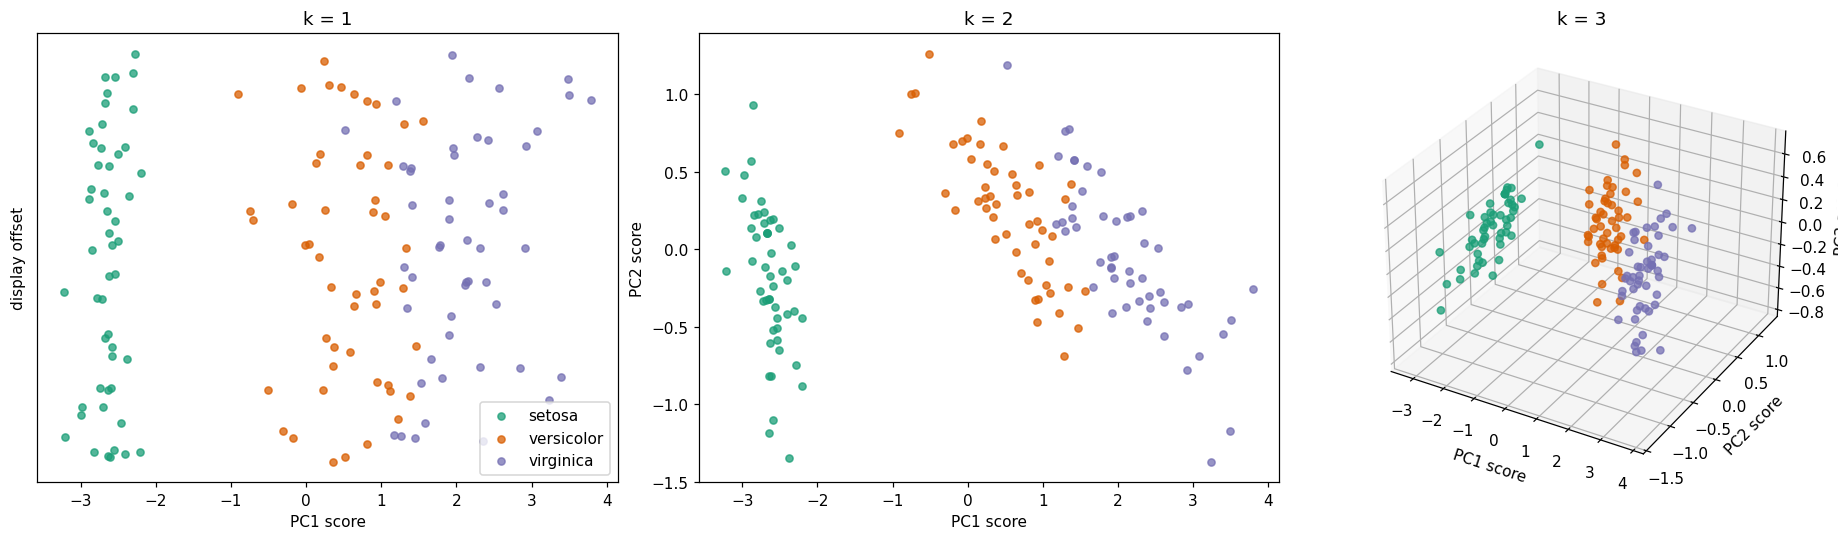

In [6]:
scores = Xc @ Vt.T
colors = {'setosa': '#1b9e77', 'versicolor': '#d95f02', 'virginica': '#7570b3'}
fig = plt.figure(figsize=(17, 4.8), constrained_layout=True)
ax1 = fig.add_subplot(131)
ax2 = fig.add_subplot(132)
ax3 = fig.add_subplot(133, projection='3d')
rng = np.random.default_rng(345)
for name, color in colors.items():
    mask = species == name
    ax1.scatter(scores[mask, 0], rng.uniform(-.08, .08, mask.sum()),
                label=name, c=color, alpha=.75, s=22)
    ax2.scatter(scores[mask, 0], scores[mask, 1], c=color, alpha=.75, s=22)
    ax3.scatter(scores[mask, 0], scores[mask, 1], scores[mask, 2],
                c=color, alpha=.75, s=22)
ax1.set(xlabel='PC1 score', ylabel='display offset', title='k = 1')
ax1.set_yticks([])
ax2.set(xlabel='PC1 score', ylabel='PC2 score', title='k = 2')
ax3.set(xlabel='PC1 score', ylabel='PC2 score', zlabel='PC3 score', title='k = 3')
ax1.legend()
plt.show()


**Interpretation.** Setosa is well separated along the first axis. Versicolor and virginica overlap more in 1D; the second axis spreads their point clouds and makes their partial separation clearer. The third axis adds some structure but does not make those two species completely distinct.


## Q11(d). Why are two axes useful, and what do the singular values mean?

**Answer.** The first two axes retain about **97.76%** of the centered squared variation: $s_1^2+s_2^2$ divided by $\sum_j s_j^2$. That makes a 2D view a good summary of the dataset's geometry, even though it does not perfectly classify species. Each singular value $s_j$ is the size of the data along its corresponding principal direction: $s_j^2$ is that direction's sum of squared centered scores, and $s_j^2/(150-1)$ is its sample variance.
